In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftshift, fftfreq

plt.ion()   # enables interactive mode so both windows stay open and update

# ========================
# Parameters
# ========================
# constants
hbar = 1.0
m = 1.0
a = 2.0
V0 = 5.0

# spatial grid
x_min, x_max, N_x = -30.0, 30.0, 1024
x_grid = np.linspace(x_min, x_max, N_x)
dx = x_grid[1] - x_grid[0]
V_potential = np.where(np.abs(x_grid) <= a, -V0, 0.0)   # defines potential barrier

# initial wave packet
x0 = -15.0
sigma0 = 1.5
k0 = 2.5
E_scatt = (hbar**2 * k0**2) / (2 * m)

# momentum grid
k_min = k0 - 4.0 / sigma0
k_max = k0 + 4.0 / sigma0
N_k = 250
k_grid = np.linspace(k_min, k_max, N_k)
dk = k_grid[1] - k_grid[0]  

# FFT momentum grid
k_grid_fft = fftshift(fftfreq(N_x, dx)) * 2 *np.pi

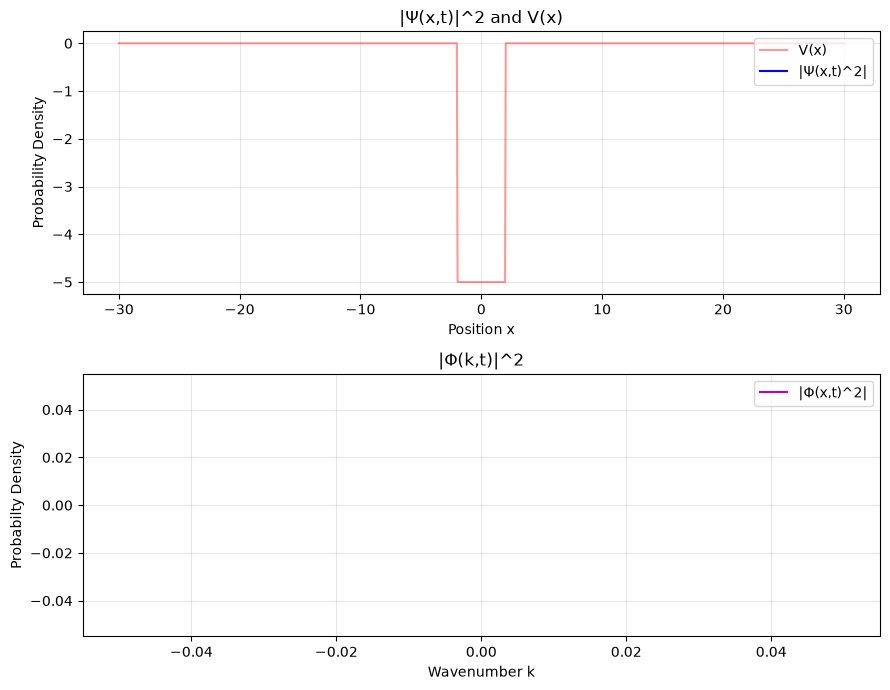

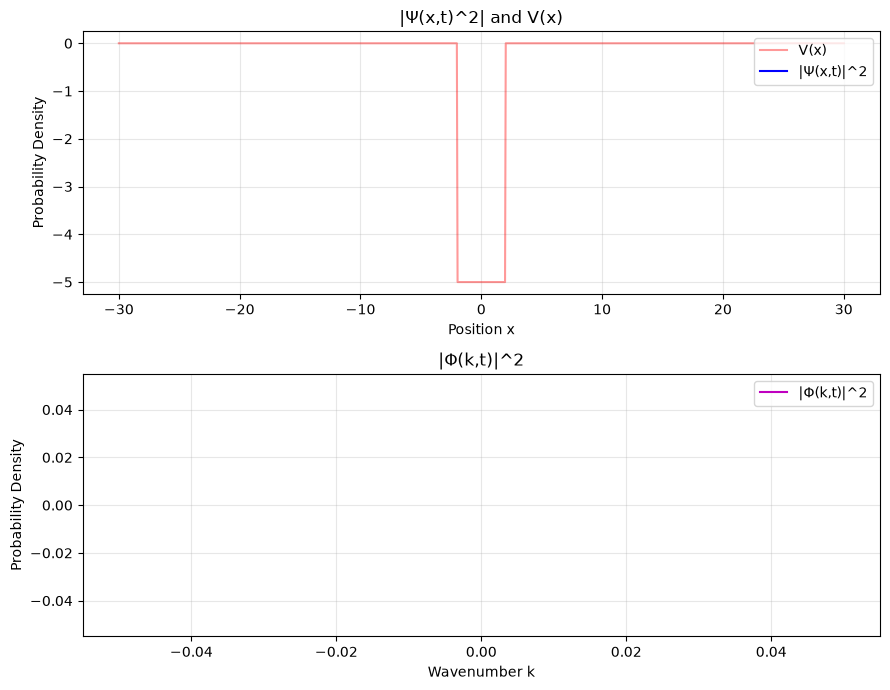

In [12]:
# ========================================
# 1. Window 1: Bound States (-V_0 < E <0) 
# ========================================
fig_bound, (ax_bound_x, ax_bound_k) = plt.subplots(2, 1, figsize=(9, 7))
fig_bound.canvas.manager.set_window_title("Bound States (-V_0 < E < 0)")

# Upper Panel: position-space, |Ψ(x,t)|^2
ax_bound_x.set_title("|Ψ(x,t)|^2 and V(x)")
ax_bound_x.set_xlabel("Position x")
ax_bound_x.set_ylabel("Probability Density")
#x_bound_x.set_xlim(-10, 10)
#ax_bound_x.set_ylim(-(V0+1), 1)
ax_bound_x.grid(True, alpha=0.3)
ax_bound_x.plot(x_grid, V_potential, 'r-', alpha=0.4, label="V(x)")

# Lower Panel: momentum-space, |Φ(k,t)|^2
ax_bound_k.set_title("|Φ(k,t)|^2")
ax_bound_k.set_xlabel("Wavenumber k")
ax_bound_k.set_ylabel("Probabilty Density")
#ax_bound_k.set_xlim(-5, 5)
ax_bound_k.grid(True, alpha=0.3)

# Animation Updates
line_bound_x, = ax_bound_x.plot([], [], 'b-', label="|Ψ(x,t)^2|")
line_bound_k, = ax_bound_k.plot([], [], 'm-', label="|Φ(x,t)^2|")
ax_bound_x.legend(loc="upper right")
ax_bound_k.legend(loc="upper right")
fig_bound.tight_layout()

# =======================================
# 2. Window 2: Scattering States (E > 0) 
# =======================================
fig_scatt, (ax_scatt_x, ax_scatt_k) = plt.subplots(2, 1, figsize=(9, 7))
fig_scatt.canvas.manager.set_window_title("Scattering States (E > 0)")

# Upper-Panel: position space, |Ψ(x,t)|^2
ax_scatt_x.set_title("|Ψ(x,t)^2| and V(x)")
ax_scatt_x.set_xlabel("Position x")
ax_scatt_x.set_ylabel("Probability Density")
#ax_scatt_x.set_xlim(-25, 25)
#ax_scatt_x.set_ylim(-(V0+1), E_scatt+4)
ax_scatt_x.grid(True, alpha=0.3)
ax_scatt_x.plot(x_grid, V_potential, 'r-', alpha=0.4, label="V(x)")

# Lower-Panel: momentum space, |Φ(k,t)|^2
ax_scatt_k.set_title("|Φ(k,t)|^2")
ax_scatt_k.set_xlabel("Wavenumber k")
ax_scatt_k.set_ylabel("Probability Density")
#ax_scatt_k.xlim(-7, 7)
ax_scatt_k.grid(True, alpha=0.3)

# Animation Updates
line_scatt_x, = ax_scatt_x.plot([], [], 'b-', label="|Ψ(x,t)|^2")
line_scatt_k, = ax_scatt_k.plot([], [], 'm-', label="|Φ(k,t)|^2")
ax_scatt_x.legend(loc="upper right")
ax_scatt_k.legend(loc="upper right")
fig_scatt.tight_layout()
fig_scatt.tight_layout()

plt.show()

In [16]:
# ==============================
# 3. Transcendental Root Solver
# ==============================
from scipy.optimize import root_scalar

def solve_bound_states(a, V0, m, hbar, x_grid):
    z0 = a * np.sqrt(2*m*V0) / hbar
    bound_states = []

    # transcendental equations
    f_even = lambda z: z * np.tan(z) - np.sqrt(z0**2 - z**2)
    f_odd = lambda z: -z / np.tan(z) - np.sqrt(z0**2 - z**2)

    # look for roots in intervals of pi/2
    n_max = int(np.ceil(2 * z0 / np.pi))
    for n in range(n_max):
        z_min = n * np.pi / 2 + 1e-4        # doesn't allow loop to blow up to infinity by shifting numerical solver
        z_max = min((n+1) * np.pi / 2 - 1e-4, z0 - 1e-4)
        if z_min >= z_max:
            continue

        is_even = (n % 2 == 0)
        f = f_even if is_even else f_odd
        if f(z_min) * f(z_max) < 0:
            res = root_scalar(f, bracket=[z_min, z_max])
            if res.converged:
                z_val = res.root
                q_val = z_val / a
                kappa_val = np.sqrt(z0**2 - z_val**2) / a
                E_val = - (hbar**2 * kappa_val**2) / (2*m) 

            # piecewise spatial wavefunction construction
            psi_b = np.zeros_like(x_grid)
            region1, region2, region3 = x_grid < -a, np.abs(x_grid) <= a, x_grid > a

            # even parity
            if n % 2 == 0: 
                C = np.cos(q_val*a) * np.exp(kappa_val*a)
                psi_b[region1] = C * np.exp(kappa_val*x_grid[region1])
                psi_b[region2] = np.cos(q_val * x_grid[region2])    
                psi_b[region3] = C * np.exp(-kappa_val*x_grid[region3])
            else:
                C = np.sin(q_val*a) * np.exp(kappa_val*a)
                psi_b[region1] = -C * np.exp(kappa_val*x_grid[region1])
                psi_b[region2] = np.sin(q_val * x_grid[region2])
                psi_b[region3] = C * np.exp(-kappa_val*x_grid[region3])

            # normalize wavefunction
            norm = np.sqrt(np.sum(np.abs(psi_b)**2) * dx)
            psi_b /= norm

            # append valid bound states
            bound_states.append({
                'n': len(bound_states),
                'E': E_val,
                'psi': psi_b,
                'parity': 'even' if is_even else 'odd'
            })

    return bound_states

# compute bound states
bound_states = solve_bound_states(a, V0, m, hbar, x_grid)

# print found energy levels
print(f"Found {len(bound_states)} bound states.")
for b in bound_states:
    print(f"  n = {b['n']} ({b['parity']}): E{b['n']} = {b['E']:.4f}")


Found 5 bound states.
  n = 0 (even): E0 = -4.7705
  n = 1 (odd): E1 = -4.0884
  n = 2 (even): E2 = -2.9770
  n = 3 (odd): E3 = -1.4995
  n = 4 (even): E4 = -0.0069
